# Práctica 1: revisión de SageMath
É necesario usar un Jupyter Notebook con Kernel SageMath, ben en [cocalc.com](https://www.cocalc.com), ben nunha instalación local de SageMath. 

## Empezando con Sage
Unha variable `a` (ou _obxecto_) pode ser dunha _clase_, por exemplo `Rational`, e ter un valor (ou _atributo_), 1/3. As funcións (ou _métodos_) da clase como `type` permiten interaccionar co obxecto.

In [2]:
a = 1/3
type(a)

<class 'sage.rings.rational.Rational'>

O método `parent` da unha descripción máis entendible da clase á que pertence.

In [3]:
parent(a)

Rational Field

En cálculo numérico traballaremos con números máquina (reais de punto flotante con 35 bits de precisión para a mantisa).

In [4]:
a = 1/3.
type(a), parent(a)

(<class 'sage.rings.real_mpfr.RealNumber'>,
 Real Field with 53 bits of precision)

Se non se indica (co punto decimal), SageMath traballa con representación exacta (cálculo simbólico).

In [5]:
a = sin(1/3)
a, type(a)

(sin(1/3), <class 'sage.symbolic.expression.Expression'>)

O método `n` permite obter o número máquina máis próximo. Obsérvese que, neste caso, pódese usar a notación _método(obxecto)_ e tamén _obxecto.método()_.

In [6]:
n(a), a.n() # Algunos objetos no permiten que se invoque el método como un 'standalone'.

(0.327194696796152, 0.327194696796152)

In [7]:
n(a,digits=4), a.n(digits=4) # En este caso se llama al mismo método de dos formas 'distintas'.

(0.3272, 0.3272)

Un exemplo máis elaborado que pasa do expresión simbólica `pi/2` ao número máquina `(pi/2).n()` e á cadea `str((pi/2).n())`. Obsérvese que `+` actúa de xeito distinto entre cadeas.

In [8]:
print('O resultado é '+str((pi/2).n()))

O resultado é 1.57079632679490


Unha clase de números máquina [equivalente](https://ask.sagemath.org/question/9991/what-are-the-differences-between-realdoublefield-and-realfield53/) a `real_mpfr.RealNumber` é `RDF`. O seu método `epsilon` devolve o valor de $\varepsilon$.

In [9]:
RDF.epsilon()

2.220446049250313e-16

## Expresións simbólicas en Sage
Ao inicio dunha sesión de Sage, `x` xa é unha expresión simbólica. Calquer outra variable débese converter explíctamente.

In [10]:
type(x)

<class 'sage.symbolic.expression.Expression'>

In [11]:
var('t')
type(t)

<class 'sage.symbolic.expression.Expression'>

O resto de expresións simbólicas se constrúen a partir destas:

In [12]:
f(x) = sin(x/2)
type(f)

<class 'sage.symbolic.expression.Expression'>

As expresións simbólicas permiten facer cálculos simbólicos.

In [13]:
limit(f, x=0)

x |--> 0

In [14]:
show(diff(f,x))

x |--> 1/2*cos(1/2*x)

A expresión anterior pódese gardar e usar como imaxe. O método `save` permite facer esto automáticamente desde o código.

In [15]:
g = plot(f(x), 0, 1)
g.save('grafica.png')

## Arrays en SageMath
Python permite usar listas (obxectos mutables) e tuplas (obxectos inmutables).

In [16]:
l = [1,2,3]
l.append(4)
l

[1, 2, 3, 4]

In [17]:
t = (1,2,3) # t.append(4) devolve erro
t

(1, 2, 3)

É máis rápido iterar sobre tuplas que sobre listas, polo que se prefiren aquelas nos bucles.

In [24]:
for i in (1,2,3):
    print(i)

1
2
3


As listas non son vectores. Para elo temos a clase `vector` de SageMath.

In [40]:
2*l

[1, 2, 3, 4, 1, 2, 3, 4]

In [41]:
v = vector(RDF, [1,2,3,4])
2*v

(2.0, 4.0, 6.0, 8.0)

O operador `[primero,segundo..ultimo]` permite xerar listas de xeito sinxelo.

In [42]:
[1..9]

[1, 2, 3, 4, 5, 6, 7, 8, 9]

In [43]:
[1,3..9]

[1, 3, 5, 7, 9]

O método `range` é o preferido cando se debe iterar nos índices dunha lista ou vector.

In [44]:
[1/v[i] for i in range(len(v))]

[1.0, 0.5, 0.3333333333333333, 0.25]

Python permite listas de listas.

In [45]:
L = [[1,2],[2,3]]
L[0][0]

1

Pero as matrices obtéñense coa clase `matrix` de SageMath. Obsérvese a notación `[fila,columna]` neste caso.

In [46]:
A = matrix(RDF,[[1,2],[2,3]])
# equivalentemente, A = matrix(RDF, 2, 2, [1,2,2,3])
A[0,0]

1.0

Métodos para matrices (non dispoñibles para listas de listas).

In [47]:
A.nrows(), A.ncols(), A.rank(), A.det(), A.transpose(), A.inverse() #etc.

(
               [1.0 2.0]  [-3.0  2.0]
2, 2, 2, -1.0, [2.0 3.0], [ 2.0 -1.0]
)

Hai máis formas de crear matrices.

In [48]:
matrix(RDF, 2), matrix.ones(RDF, 2, 3), matrix.identity(RDF, 2), matrix.random(RDF,2)

(
[0.0 0.0]  [1.0 1.0 1.0]  [1.0 0.0]
[0.0 0.0], [1.0 1.0 1.0], [0.0 1.0],

[ -0.284577124196135 -0.9234582613145146]
[  0.895074165231273 0.10209254380071453]
)

Ou dando unha regra.

In [49]:
A = matrix(RDF, 2, 2, lambda i,j: i+j+1)
A

[1.0 2.0]
[2.0 3.0]

O método `apply_map` permite aplicar unha función a cada compoñente dun vector ou matriz.

In [50]:
f(x) = sin(x/2)
A.apply_map(f)

[ 0.479425538604203 0.8414709848078965]
[0.8414709848078965 0.9974949866040544]

O método `map` fai o equivalente para listas Python.

In [51]:
l = [1..4]
list(map(f,l))

[sin(1/2), sin(1), sin(3/2), sin(2)]

O operador `\` implementa o método de descomposición de Gauss con pivote.

In [52]:
A = matrix(RDF, [[1,2],[2,3]])
b = vector(RDF,[1,5])
A\b #solución de A*x=b

(7.0, -3.0)

## Programación en Sage

As funcións `def` permiten implementar un _algoritmo_.

In [53]:
def f(x):
    if x >= 1:
        return x-1
    else:
        return 1-x

Obsérvese que, salvo casos sinxelos equiparables a unha expresión simbólica, xa non é posible facer cálculo simbólico.

In [54]:
diff(f(x)) # x >= 1 é sempre falso!

-1

As funcións `lambda` son funcións que se poden escribir nunha liña e poden ser usadas como argumento doutras funcións ou métodos.

In [55]:
A = matrix(RDF, 2, 2, lambda i,j: i+j+1)

Os archivos `.sage` permiten crear "librarías"  de funcións (ver `my_plots.sage`)

In [1]:
load('my_plots.sage')

In [57]:
help(plotNsave)

Help on function plotNsave in module __main__:

plotNsave(f, a, b, file)
    Aqui se pon a documentacion da funcion.
    Esta informacion mostrase ao escribir plotNsave? ou help(plotNsave).



Agora podemos usar as funcións do ficheiro \`.sage\`.


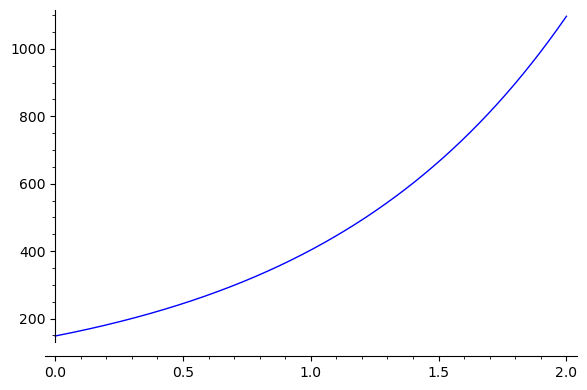

In [4]:
plotNsave(lambda x: exp(x+5), 0, 2, 'exp.png') # El 'lambda' permite crear funciones 'al vuelo'

Exemplo de como usar `for` para a suma $\sum_{n=1}^{100}\frac{1}{n^4}$.


In [5]:
sum(1/n.n()^4 for n in (1..100))

1.08232290534447

Exemplo de como usar `while` para a suma $\sum_{n=1}^{\infty}\frac{1}{n^4}$.


In [11]:
def serie(tol):
    suma = 0.
    n = 1
    term = 1/n^4
    while term > tol:
        suma += term
        n += 1 
        term = 1/n^4
    return suma

serie(1.e-14)

1.08232323370060

In [12]:
matrix(RDF,5,5,2)

[2.0 0.0 0.0 0.0 0.0]
[0.0 2.0 0.0 0.0 0.0]
[0.0 0.0 2.0 0.0 0.0]
[0.0 0.0 0.0 2.0 0.0]
[0.0 0.0 0.0 0.0 2.0]

In [13]:
help(plotNsave)

Help on function plotNsave in module __main__:

plotNsave(f, a, b, file)
    Aqui se pon a documentacion da funcion.
    Esta informacion mostrase ao escribir plotNsave? ou help(plotNsave).

